# 03 — What changed between December 2025 and September 2026?

Notebooks 01–02 looked at one Barcelona snapshot. Here: **four quarterly
Barcelona snapshots** (Dec 2025, Mar, Jun, Sep 2026) and the same months in
**Madrid, Valencia, Málaga and Sevilla**.

Why the other cities matter: on **1 January 2026** Catalonia extended its rent
cap to seasonal lets (Llei 11/2025, see `POLICY_LEVERS`). That law does not
apply in Madrid, Valencia or Andalucía. If something changes in Barcelona
*and not elsewhere*, timing points at a Catalan cause; if it changes
everywhere, it does not. This is a comparison, not an experiment — the cities
differ in many other ways.

**One rule for every snapshot:** only *active* listings (at least one open
date) are counted. See `data/README.md` for why.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src import config as cfg
from src import cleaning, metrics
from src import sources as src

sns.set_theme(style="whitegrid", palette="colorblind")

snapshots = {
    (city, date): cleaning.add_columns(cleaning.load_snapshot(city, date))
    for city, dates in src.SNAPSHOTS.items()
    for date in dates
}
print(f"{len(snapshots)} snapshots loaded")

12 snapshots loaded


## The headline numbers, every city and snapshot

`share_month_plus` = active listings asking **31 nights or more**. It is
used for cross-city comparison instead of the Catalan stay bands, because the
legal tourist/seasonal line differs between regions.

In [2]:
summary = pd.DataFrame([
    {"city": city, "snapshot": date, **metrics.snapshot_summary(df),
     "top_1pct_hosts": metrics.top_host_share(df, 1)}
    for (city, date), df in snapshots.items()
]).set_index(["city", "snapshot"])
summary

listings  active  share_31_nights  share_month_plus  \
city      snapshot                                                          
barcelona 2025-12-14     18177   15592             18.8              42.0   
          2026-03-21     16107   13328             17.6              34.7   
          2026-06-24     15406   14017             17.6              37.1   
          2026-09-17     15236   11737             19.5              41.7   
madrid    2025-12-14     24616   19830              4.9               8.5   
          2026-09-17     23109   17561              4.6               7.8   
valencia  2025-12-27      7702    7219              0.6               2.1   
          2026-09-20      7968    6236              0.9               2.0   
malaga    2025-12-31      8811    8728              0.2               2.1   
          2026-09-28      9505    7385              0.1               2.3   
sevilla   2025-12-30      7674    7561              0.1               1.7   
          2026-09-25      8375    6474              0.1               2.4   

                      share_tourist_licence  share_nrua_seasonal  \
city      snapshot                                                 
barcelona 2025-12-14                   36.0                 15.5   
          2026-03-21                   47.7                 20.5   
          2026-06-24                   51.0                 24.6   
          2026-09-17                   45.4                 21.6   
madrid    2025-12-14                    6.7                 31.1   
          2026-09-17                    9.4                 39.1   
valencia  2025-12-27                   27.8                 18.8   
          2026-09-20                   38.8                 25.8   
malaga    2025-12-31                   55.6                  1.3   
          2026-09-28                   73.8                  1.3   
sevilla   2025-12-30                   54.5                  0.6   
          2026-09-25                   72.2                  1.2   

                      share_professional  share_entire_home  median_price  \
city      snapshot                                                          
barcelona 2025-12-14                68.1               71.0           NaN   
          2026-03-21                66.7               75.9         174.0   
          2026-06-24                66.8               75.0         175.0   
          2026-09-17                65.0               71.3         176.0   
madrid    2025-12-14                56.6               71.6           NaN   
          2026-09-17                54.6               69.8         147.0   
valencia  2025-12-27                42.7               76.5           NaN   
          2026-09-20                43.6               75.3         130.0   
malaga    2025-12-31                51.9               89.4           NaN   
          2026-09-28                53.0               87.2         150.0   
sevilla   2025-12-30                51.0               86.9           NaN   
          2026-09-25                50.8               84.4         153.0   

                      top_1pct_hosts  
city      snapshot                    
barcelona 2025-12-14            30.9  
          2026-03-21            29.0  
          2026-06-24            29.5  
          2026-09-17            28.6  
madrid    2025-12-14            27.3  
          2026-09-17            27.5  
valencia  2025-12-27            16.4  
          2026-09-20            16.1  
malaga    2025-12-31            22.7  
          2026-09-28            23.8  
sevilla   2025-12-30            19.2  
          2026-09-25            20.1

Dec 2025 prices are empty in every city (an Inside Airbnb gap), so
`median_price` starts in 2026.

## Barcelona, quarter by quarter

,tourist,boundary,seasonal
2025-12-14,9045,2936,3611
2026-03-21,8707,2340,2281
2026-06-24,8813,2463,2741
2026-09-17,6848,2293,2596


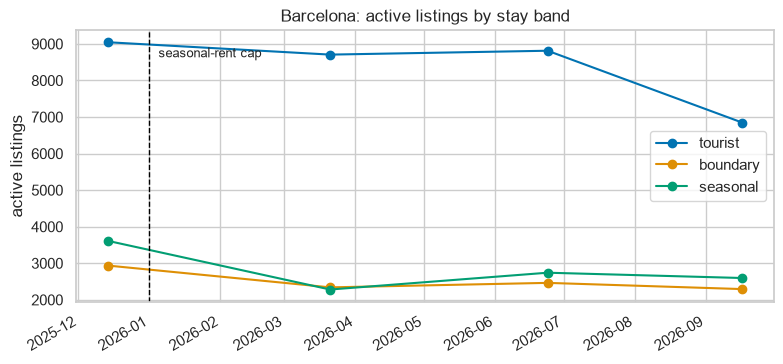

In [3]:
bcn = pd.DataFrame({
    date: metrics.band_counts(snapshots[("barcelona", date)])
    for date in src.SNAPSHOTS["barcelona"]
}).T
bcn.index = pd.to_datetime(bcn.index)

fig, ax = plt.subplots(figsize=(9, 4))
bcn.plot(ax=ax, marker="o")
ax.axvline(pd.Timestamp(cfg.POLICY_LEVERS["seasonal_rentals"]["applies_from"]),
           color="black", ls="--", lw=1)
ax.text(pd.Timestamp("2026-01-05"), ax.get_ylim()[1] * 0.92, "seasonal-rent cap", fontsize=9)
ax.set_ylabel("active listings"); ax.set_xlabel("")
ax.set_title("Barcelona: active listings by stay band")
fig.savefig(cfg.FIGURES_DIR / "03_barcelona_bands.png", dpi=150, bbox_inches="tight")
bcn

Between December and March the seasonal band shrank by about a third
and the boundary band by a fifth, while the tourist band barely moved. By
September both had partly recovered.

The tourist band's drop in **September** is a different story: it coincides
with the jump in listings with no open dates that hits *every* city in the
September snapshots (see `data/README.md`), so it is not read as a Barcelona
effect.

**What this cannot show:** a snapshot count mixes listings leaving, new
listings arriving and hosts changing their minimum stay. The next section
separates those by following each listing's id.

## Where did December's listings go?

Inside Airbnb keeps the same listing id across snapshots, so each active
December listing can be followed to September: same band, a different band,
still listed but with no open dates (*inactive*), or no longer in the file
(*gone*).

In [4]:
def transition_shares(city):
    dates = src.SNAPSHOTS[city]
    table = metrics.transitions(snapshots[(city, dates[0])], snapshots[(city, dates[-1])])
    return table, (table.div(table.sum(axis=1), axis=0) * 100).round(1)

bcn_table, bcn_shares = transition_shares("barcelona")
mad_table, mad_shares = transition_shares("madrid")
print("Barcelona, Dec 2025 -> Sep 2026 (% of each December band):")
print(bcn_shares.to_string())
print()
print("Madrid, same months:")
print(mad_shares.to_string())

Barcelona, Dec 2025 -> Sep 2026 (% of each December band):
stay_band  tourist  boundary  seasonal  inactive  gone
stay_band                                             
tourist       57.9       1.1       2.3      16.5  22.1
boundary       1.8      43.7       4.3      11.0  39.2
seasonal       3.2       3.9      49.5       5.7  37.7

Madrid, same months:
stay_band  tourist  boundary  seasonal  inactive  gone
stay_band                                             
tourist       64.1       0.3       0.4      13.0  22.2
boundary       8.6      51.9       1.9      10.2  27.4
seasonal      28.7       1.7      39.0      10.6  20.0


In Barcelona, December's seasonal and boundary listings were much more
likely to be **gone** by September than its tourist listings. In Madrid the
exit rates are similar across bands.

Hosts who left may have moved to other platforms, switched to long-term
leases, sold, or simply stopped — the file cannot tell which.

## Test — is Barcelona's exit gap different from Madrid's?

A **difference-in-differences of proportions**:

- gap = (exit rate of month-plus listings) − (exit rate of tourist listings)
- compare Barcelona's gap with Madrid's gap

Month-plus = boundary + seasonal (31+ nights), the same definition in both
cities. The standard error combines four independent proportions; the 95% CI
is ±1.96 SE. **H0:** the two gaps are equal.

Madrid comes first because it has the largest month-plus segment after
Barcelona; the robustness check below repeats it for every city.

In [5]:
def exit_counts(table):
    """(exits, total) for month-plus and tourist listings."""
    month_plus = table.loc[["boundary", "seasonal"]].sum()
    tourist = table.loc["tourist"]
    return (month_plus["gone"], month_plus.sum()), (tourist["gone"], tourist.sum())


def gap_and_se(table):
    (x1, n1), (x2, n2) = exit_counts(table)
    p1, p2 = x1 / n1, x2 / n2
    return p1 - p2, p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2


gaps = {}
for city, table in [("barcelona", bcn_table), ("madrid", mad_table)]:
    gap, var = gap_and_se(table)
    gaps[city] = (gap, var)
    print(f"{city:9}: month-plus exit rate minus tourist exit rate = {gap * 100:+.1f} points")

did = gaps["barcelona"][0] - gaps["madrid"][0]
se = np.sqrt(gaps["barcelona"][1] + gaps["madrid"][1])
z = did / se
p_value = 2 * stats.norm.sf(abs(z))   # sf keeps precision for large z
print(f"\ndifference of the gaps: {did * 100:+.1f} points, "
      f"95% CI [{(did - 1.96 * se) * 100:+.1f}, {(did + 1.96 * se) * 100:+.1f}], "
      f"z = {z:.1f}, p = {p_value:.1e}")

barcelona: month-plus exit rate minus tourist exit rate = +16.3 points
madrid   : month-plus exit rate minus tourist exit rate = +2.1 points

difference of the gaps: +14.3 points, 95% CI [+11.7, +16.8], z = 10.8, p = 2.4e-27


**Robustness:** the same gap in every comparison city, not only Madrid.
Month-plus listings are rare outside Barcelona and Madrid, so their intervals
are wide.

In [6]:
rows = []
for city, dates in src.SNAPSHOTS.items():
    table = metrics.transitions(snapshots[(city, dates[0])], snapshots[(city, dates[-1])])
    gap, var = gap_and_se(table)
    n_month_plus = table.loc[["boundary", "seasonal"]].to_numpy().sum()
    rows.append({"city": city, "month_plus_listings_dec": int(n_month_plus),
                 "exit_gap_points": round(gap * 100, 1),
                 "ci_low": round((gap - 1.96 * np.sqrt(var)) * 100, 1),
                 "ci_high": round((gap + 1.96 * np.sqrt(var)) * 100, 1)})
pd.DataFrame(rows).set_index("city")

,month_plus_listings_dec,exit_gap_points,ci_low,ci_high
city,,,,
barcelona,6547,16.3,14.9,17.8
madrid,1691,2.1,-0.1,4.2
valencia,152,12.1,4.8,19.4
malaga,182,21.1,14.1,28.0
sevilla,132,15.5,8.0,23.0


**This changes the reading.** Against Madrid alone, Barcelona's gap looks
exceptional. Against all four cities it does not: Valencia, Málaga and
Sevilla — none of them under the Catalan law — show gaps of the same size,
with overlapping intervals. **Madrid is the outlier, not Barcelona.**

So the evidence does **not** support "the seasonal-rent cap pushed month-plus
listings off Airbnb". The more general pattern is that month-plus listings
churn faster than tourist ones in most Spanish cities. A one-city comparison
would have overstated a Catalan effect — which is why every comparison here
uses all four cities.

What *is* specific to Barcelona is the **size** of its month-plus segment
(~40% of active listings, vs 2–9% elsewhere) and the dip in the seasonal band
between December and March. The other cities have no March snapshot, so that
dip cannot be compared — and without a previous year it cannot be separated
from an ordinary winter pattern either.

## Licence display rose everywhere

If one city's licence share rose because of a local rule, the others should
stay flat. They did not:

In [7]:
# Snapshot dates differ by a few days between cities: label by round
first_last = {city: {"Dec 2025": dates[0], "Sep 2026": dates[-1]} for city, dates in src.SNAPSHOTS.items()}
licence = pd.DataFrame({
    city: {label: summary.loc[(city, date), "share_tourist_licence"] for label, date in rounds.items()}
    for city, rounds in first_last.items()
}).T
licence.assign(change=licence["Sep 2026"] - licence["Dec 2025"])

,Dec 2025,Sep 2026,change
barcelona,36.0,45.4,9.4
madrid,6.7,9.4,2.7
valencia,27.8,38.8,11.0
malaga,55.6,73.8,18.2
sevilla,54.5,72.2,17.7


Every city shows more listings with a regional tourist-flat number in
September than in December. That points at something national or
platform-wide (registration enforcement) rather than a Catalan rule.
Outside Catalonia these shares are a lower bound (see `data/README.md`).

## Who supplies the market? Concentration in each city

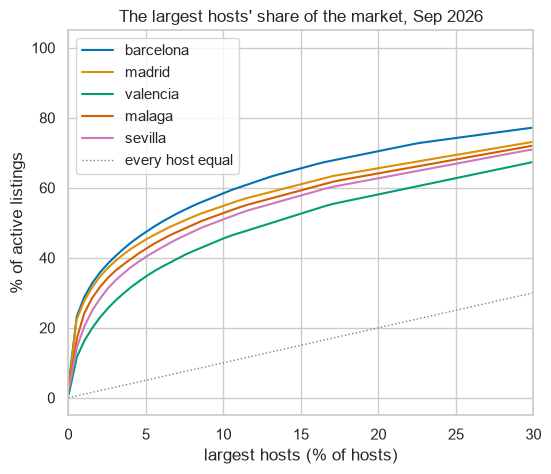

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
for city, dates in src.SNAPSHOTS.items():
    curve = metrics.concentration_curve(snapshots[(city, dates[-1])], points=200)
    ax.plot(curve["host_share"], curve["listing_share"], label=city)
ax.plot([0, 100], [0, 100], color="grey", ls=":", lw=1, label="every host equal")
ax.set_xlim(0, 30)
ax.set_xlabel("largest hosts (% of hosts)"); ax.set_ylabel("% of active listings")
ax.set_title("The largest hosts' share of the market, Sep 2026")
ax.legend()
fig.savefig(cfg.FIGURES_DIR / "03_concentration.png", dpi=150, bbox_inches="tight")

## What I found

1. **Barcelona's month-plus segment is unique in size.** ~40% of active
   listings ask 31+ nights (42.0% in Dec, 41.7% in Sep), vs 7.8–8.5% in
   Madrid and about 2% in Valencia, Málaga and Sevilla.
2. **It dipped after 1 January 2026.** Seasonal-band listings fell from
   3,611 (Dec) to 2,281 (Mar), then recovered to 2,596 (Sep). With no March
   snapshot elsewhere and no previous year, the dip cannot be separated
   from a seasonal pattern.
3. **Month-plus listings churn faster almost everywhere.** By September,
   Barcelona's December month-plus listings were 16.3 points more likely to
   be gone than its tourist listings (95% CI [14.9, 17.8]). Valencia,
   Málaga and Sevilla show similar gaps (12–21 points); only Madrid does
   not (2.1). The data does **not** single out the Catalan law.
4. **Licence display rose in every city** (+2.7 to +18.2 points), pointing
   at national or platform-wide registration enforcement rather than a
   local rule.
5. **The largest 1% of hosts run ~29% of Barcelona's active listings**,
   similar to Madrid (~27%) and well above Valencia (~16%).


**Next:** `04_register_and_rents.ipynb` — the official licence register
against the listings, and what official rents did over the same months.